## EDA Project - SwiftCart Retail Analysis

### Sprint 3 - Advance Statistics

In [1]:
## Importing libraries
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("swiftcart_cleaned.csv")
df

,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,171-1029312-3038738,1029312.0,Women,37,Adult,2022-12-04,Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376.0,MOHALI,PUNJAB,140301,IN,False
1,405-2183842-2225946,2183842.0,Women,29,Adult,2022-12-04,Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449.0,GURUGRAM,HARYANA,122002,IN,False
2,171-1641533-8921966,1641533.0,Women,67,Senior,2022-12-04,Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453.0,KOLKATA,WEST BENGAL,700029,IN,False
3,404-7490807-6300351,7490807.0,Women,20,Adult,2022-12-04,Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729.0,THANJAVUR,TAMIL NADU,613007,IN,False
4,403-9293516-4577154,9293516.0,Women,62,Senior,2022-12-04,Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544.0,GURUGRAM,HARYANA,122001,IN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31019,405-4724097-1016369,4724097.0,Men,60,Senior,2022-01-06,Jan,Delivered,Flipkart,J0083-KR-XL,kurta,XL,1,INR,565.0,PUNE,MAHARASHTRA,412307,IN,False
31020,405-4724097-1016369,4724097.0,Men,37,Adult,2022-01-06,Jan,Delivered,Myntra,J0010-LCD-S,Set,S,1,INR,939.0,BENGALURU,KARNATAKA,560061,IN,False
31021,408-3572295-5992330,3572295.0,Men,29,Adult,2022-01-06,Jan,Delivered,Amazon,SET398-KR-PP-L,Set,L,1,INR,1115.0,PITHORAGARH,UTTARAKHAND,262501,IN,False
31022,405-1423498-9705162,1423498.0,Men,46,Adult,2022-01-06,Jan,Delivered,Amazon,JNE3568-KR-M,kurta,M,1,INR,399.0,DHULE,MAHARASHTRA,424006,IN,False


In [4]:
cols = ['Age', 'Qty', 'Amount']

central_tendency = pd.DataFrame({
    'Mean': df[cols].mean(),
    'Median': df[cols].median(),
    'Mode': df[cols].mode().iloc[0]
})

print(central_tendency.round(2))

          Mean  Median   Mode
Age      39.39    37.0   37.0
Qty       1.01     1.0    1.0
Amount  682.16   646.0  399.0


In [5]:
dispersion = pd.DataFrame({
    'Range': df[cols].max() - df[cols].min(),
    'Variance': df[cols].var(),
    'Standard_Deviation': df[cols].std(),
    'IQR': df[cols].quantile(0.75) - df[cols].quantile(0.25)
})

print(dispersion.round(2))

         Range  Variance  Standard_Deviation    IQR
Age       60.0    220.52               14.85   19.0
Qty       19.0      0.09                0.29    0.0
Amount  2807.0  72145.68              268.60  308.0


In [6]:
percentiles = df[cols].quantile([
    0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
])

print(percentiles.round(2))

       Age  Qty  Amount
0.10  22.0  1.0   380.0
0.25  28.0  1.0   486.0
0.50  37.0  1.0   646.0
0.75  47.0  1.0   794.0
0.90  63.0  1.0  1099.0
0.95  71.0  1.0  1186.0
0.99  77.0  1.0  1442.0


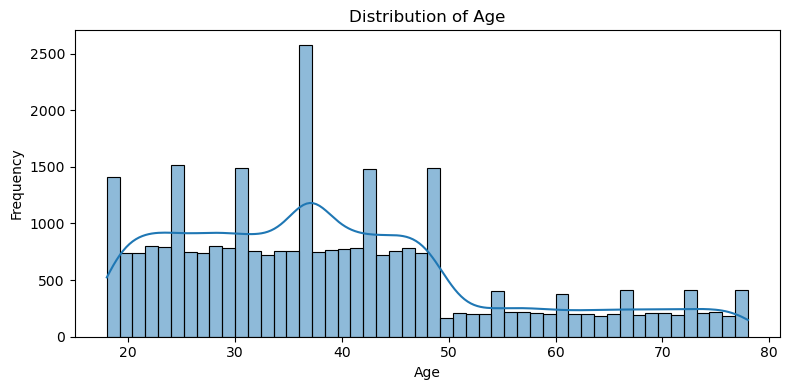

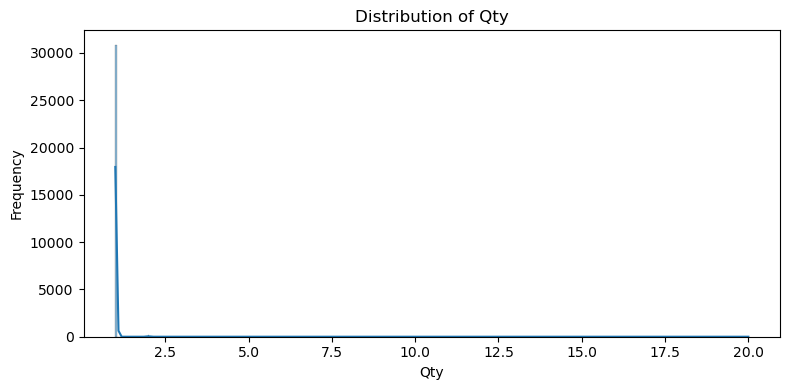

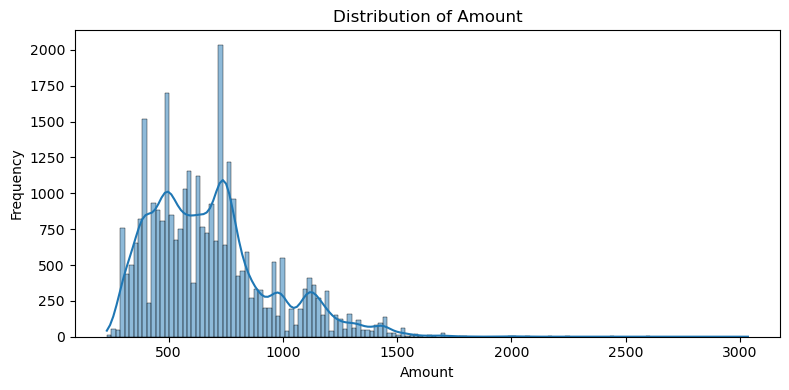

In [7]:
for col in cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

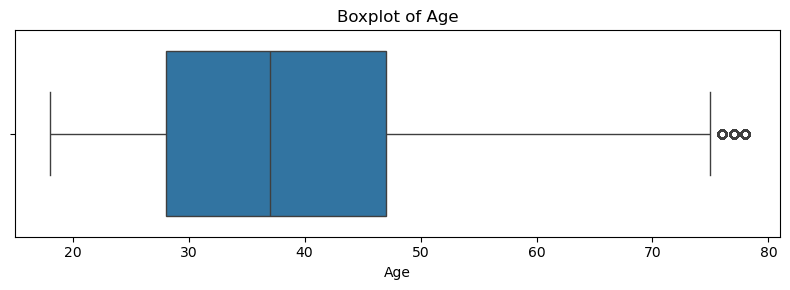

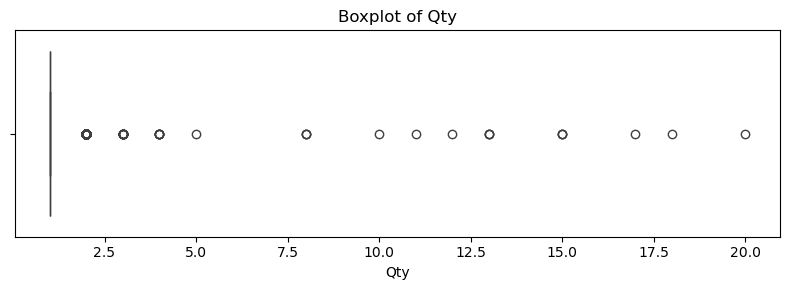

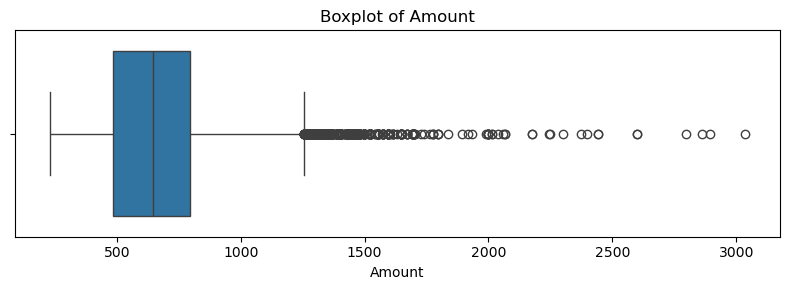

In [8]:
for col in cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

In [9]:
shape_stats = pd.DataFrame({
    'Skewness': df[cols].skew(),
    'Kurtosis': df[cols].kurt()
})

print(shape_stats.round(3))

        Skewness  Kurtosis
Age        0.760    -0.039
Qty       43.710  2188.946
Amount     1.053     1.769


          Age    Qty  Amount
Age     1.000 -0.001   0.002
Qty    -0.001  1.000   0.054
Amount  0.002  0.054   1.000


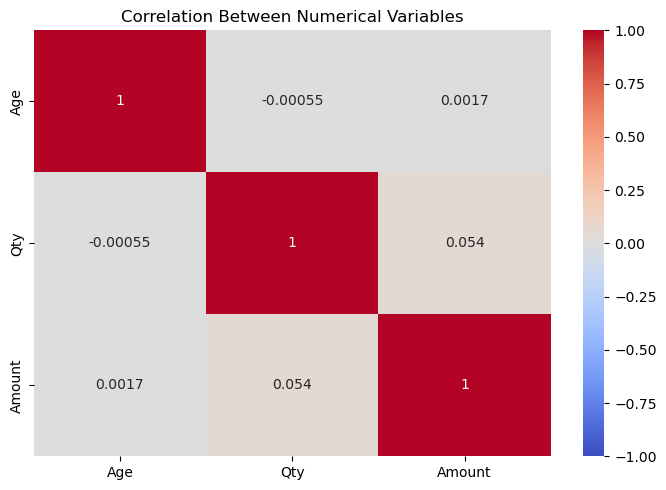

In [10]:
correlation = df[cols].corr(method='pearson')

print(correlation.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.title('Correlation Between Numerical Variables')
plt.tight_layout()
plt.show()

            Age    Qty     Amount
Age     220.515 -0.002      6.889
Qty      -0.002  0.085      4.262
Amount    6.889  4.262  72145.675


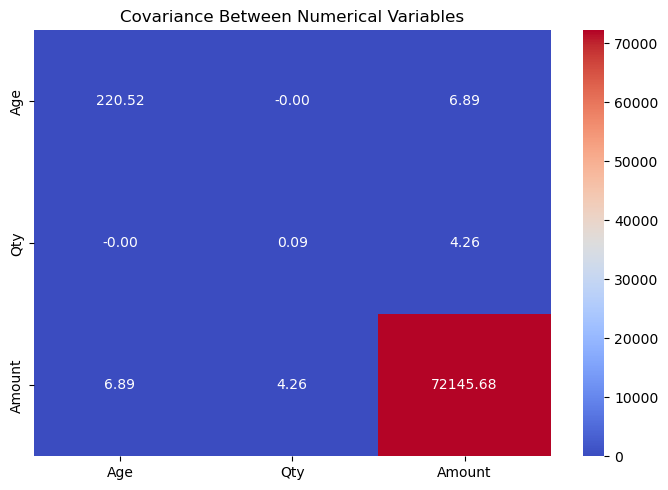

In [11]:
covariance = df[cols].cov()

print(covariance.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    covariance,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Covariance Between Numerical Variables')
plt.tight_layout()
plt.show()

In [12]:
from scipy import stats

amazon = df.loc[df['Channel'] == 'Amazon', 'Amount'].dropna()
myntra = df.loc[df['Channel'] == 'Myntra', 'Amount'].dropna()

t_stat, p_value = stats.ttest_ind(
    amazon,
    myntra,
    equal_var=False
)

print("Amazon Mean:", amazon.mean())
print("Myntra Mean:", myntra.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: The mean amounts differ significantly.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Amazon Mean: 682.7029163259743
Myntra Mean: 681.3653925762385
T-statistic: 0.3319719686536996
P-value: 0.7399148961165674
Fail to reject H0: Insufficient evidence of a difference.


In [15]:
category_groups = [
    group['Amount'].dropna().values
    for name, group in df.groupby('Category')
    if group['Amount'].notna().sum() > 0
]

f_stat, p_value = stats.f_oneway(*category_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one category mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of differences.")

F-statistic: 2877.723812610218
P-value: 0.0
Reject H0: At least one category mean differs.


In [16]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_result = pairwise_tukeyhsd(
    endog=df['Amount'].dropna(),
    groups=df.loc[df['Amount'].notna(), 'Category'],
    alpha=0.05
)

print(tukey_result)

          Multiple Comparison of Means - Tukey HSD, FWER=0.05          
    group1        group2     meandiff p-adj    lower     upper   reject
-----------------------------------------------------------------------
       Blouse        Bottom -258.7699    0.0 -341.8858  -175.654   True
       Blouse  Ethnic Dress  124.3746    0.0   67.1236  181.6257   True
       Blouse         Saree  116.9939    0.0   71.7562  162.2316   True
       Blouse           Set  232.8153    0.0  190.5347  275.0959   True
       Blouse           Top  -74.2994    0.0 -118.3294  -30.2695   True
       Blouse Western Dress  159.1666    0.0  116.1077  202.2255   True
       Blouse         kurta -140.4244    0.0 -182.7767  -98.0721   True
       Bottom  Ethnic Dress  383.1445    0.0  301.4405  464.8486   True
       Bottom         Saree  375.7638    0.0  301.9782  449.5494   True
       Bottom           Set  491.5852    0.0  419.5747  563.5957   True
       Bottom           Top  184.4705    0.0   111.419  257.5219

In [17]:
contingency_table = pd.crosstab(
    df['Channel'],
    df['Status']
)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Order status is associated with channel.")
else:
    print("Fail to reject H0: Insufficient evidence of association.")

Chi-square statistic: 10.117285788868312
Degrees of freedom: 18
P-value: 0.9280108446747661
Fail to reject H0: Insufficient evidence of association.


In [19]:
amount = df['Amount'].dropna()

mean_amount = amount.mean()
std_amount = amount.std()
n = len(amount)

confidence_level = 0.95
standard_error = std_amount / np.sqrt(n)

critical_value = stats.t.ppf(
    (1 + confidence_level) / 2,
    df=n - 1
)

lower = mean_amount - critical_value * standard_error
upper = mean_amount + critical_value * standard_error

print("Sample Mean:", round(mean_amount, 2))
print("95% Confidence Interval:", round(lower, 2), "to", round(upper, 2))
print("Sample Size:", n)

Sample Mean: 682.16
95% Confidence Interval: 679.17 to 685.15
Sample Size: 31024


In [20]:
df['Order_Month'] = pd.to_datetime(df['Date']).dt.month
df['Order_Day'] = pd.to_datetime(df['Date']).dt.day
df['Order_Year'] = pd.to_datetime(df['Date']).dt.year
df['Day_Name'] = pd.to_datetime(df['Date']).dt.day_name()

df['Is_Weekend'] = pd.to_datetime(df['Date']).dt.dayofweek >= 5

df['Sales_Category'] = pd.cut(
    df['Amount'],
    bins=[-float('inf'), 500, 1000, float('inf')],
    labels=['Low', 'Medium', 'High']
)

df['Quantity_Category'] = pd.cut(
    df['Qty'],
    bins=[-float('inf'), 1, 3, float('inf')],
    labels=['Single', 'Small_Bulk', 'Bulk']
)

df[['Order_Month', 'Day_Name', 'Is_Weekend',
    'Sales_Category', 'Quantity_Category']].head()

,Order_Month,Day_Name,Is_Weekend,Sales_Category,Quantity_Category
0,12.0,Sunday,True,Low,Single
1,12.0,Sunday,True,High,Single
2,12.0,Sunday,True,Low,Single
3,12.0,Sunday,True,Medium,Single
4,12.0,Sunday,True,Medium,Single


In [22]:
day_sales = df.groupby('Day_Name')['Amount'].agg(
    ['count', 'mean', 'sum']
).round(2)

print(day_sales)

           count    mean        sum
Day_Name                           
Friday      4433  687.94  3049649.0
Monday      3947  675.66  2666835.0
Saturday    4643  675.45  3136096.0
Sunday      4661  688.87  3210823.0
Thursday    3151  689.28  2171917.0
Tuesday     5441  680.60  3703122.0
Wednesday   4260  679.58  2895008.0


In [23]:
weekend_sales = df.groupby('Is_Weekend')['Amount'].agg(
    ['count', 'mean', 'sum']
).round(2)

print(weekend_sales)

            count    mean         sum
Is_Weekend                           
False       21720  682.16  14816483.0
True         9304  682.17   6346919.0


In [24]:
feature_documentation = pd.DataFrame({
    'Feature': [
        'Order_Month',
        'Order_Day',
        'Order_Year',
        'Day_Name',
        'Is_Weekend',
        'Sales_Category',
        'Quantity_Category'
    ],
    'Purpose': [
        'Analyze monthly sales patterns',
        'Analyze sales by date of the month',
        'Compare sales across years',
        'Identify sales patterns by weekday',
        'Compare weekday and weekend sales',
        'Group recorded amounts into bands',
        'Group records by quantity'
    ],
    'Business_Use': [
        'Monthly sales planning',
        'Identify within-month patterns',
        'Year-over-year comparison',
        'Weekly marketing planning',
        'Scheduling promotional campaigns',
        'Sales segmentation',
        'Quantity and product analysis'
    ]
})

print(feature_documentation)

             Feature                             Purpose  \
0        Order_Month      Analyze monthly sales patterns   
1          Order_Day  Analyze sales by date of the month   
2         Order_Year          Compare sales across years   
3           Day_Name  Identify sales patterns by weekday   
4         Is_Weekend   Compare weekday and weekend sales   
5     Sales_Category   Group recorded amounts into bands   
6  Quantity_Category           Group records by quantity   

                       Business_Use  
0            Monthly sales planning  
1    Identify within-month patterns  
2         Year-over-year comparison  
3         Weekly marketing planning  
4  Scheduling promotional campaigns  
5                Sales segmentation  
6     Quantity and product analysis  


## Feature engineering improved the SwiftCart dataset by transforming existing columns into useful features for analysis.

**Order_Month:** Created to identify monthly sales patterns and support sales planning.

**Order_Day:** Created to analyze sales patterns across dates within a month.

**Order_Year:** Created to compare yearly sales and track growth.

**Day_Name:** Created to analyze weekday sales. Tuesday recorded the highest total sales amount.

**Is_Weekend:** Created to compare weekday and weekend performance. Average recorded amounts were almost identical.

**Sales_Category:** Created to group amounts into Low, Medium, and High categories for easier sales segmentation.

**Quantity_Category:** Created to group records by quantity and analyze purchasing patterns.

## Final Analytical Findings — SwiftCart Sales Analysis

1. Customers

The correlation analysis showed almost no linear relationship between customer age and quantity purchased or recorded sales amount. The correlation values were approximately −0.00 and 0.00, respectively. Therefore, age alone may not be a useful indicator of purchasing quantity or recorded amount.

2. Products

The Set category had the highest total recorded sales amount of 10,502,211, followed by Kurta at 4,953,662 and Western Dress at 3,147,928. ANOVA identified significant differences in average recorded amounts across product categories, and Tukey HSD showed that most category pairs differed significantly.

3. Orders

The dataset contained multiple product rows per order, so row counts should not be treated as unique order counts. The analysis also identified missing order and customer IDs. These should be handled carefully to avoid inaccurate order-level analysis.

4. Sales

The overall average recorded amount was 682.16, with a 95% confidence interval of 679.17 to 685.15. The quantity-versus-amount correlation was approximately 0.05, indicating a very weak positive linear relationship.

5. Channels

Amazon recorded the highest total amount at 7,514,511, followed by Myntra at 4,937,855. The Welch t-test found no statistically significant difference between Amazon and Myntra's mean recorded amounts (p = 0.7399). The chi-square test also found insufficient evidence of an association between channel and order status (p = 0.9280).

6. Geography

Maharashtra had the highest recorded sales amount at 2,990,221, followed by Karnataka at 2,644,636 and Uttar Pradesh at 2,103,293. These states may be useful starting points for regional sales analysis and marketing planning.

7. Time

March had the highest monthly recorded sales amount at 1,897,253, while November had the lowest at 1,591,621. Tuesday recorded the highest total amount by weekday at 3,703,122. Weekday and weekend average amounts were almost identical, at 682.16 and 682.17, respectively.

8. Business Performance

Feature engineering improved analysis by enabling comparisons by month, weekday, weekend, sales category, and quantity category. Statistical testing identified differences among product-category averages but did not establish significant differences between Amazon and Myntra's average amounts or an association between channel and status.

## Final Business Recommendations — SwiftCart

**Customer Engagement:** Since customer age showed almost no linear relationship with quantity or recorded sales amount, 
SwiftCart should segment customers using purchase history and preferences rather than age alone.

**Product Strategy:** Prioritize inventory planning for Set, Kurta, and Western Dress, which recorded the highest category sales amounts. Review profit margins, returns, and demand before expanding inventory.

**Sales Improvement:** March had the highest monthly recorded sales amount (1,897,253), while November had the lowest (1,591,621). Investigate the reasons for this difference and test targeted promotions during lower-performing periods.

**Order Management:** Monitor cancellations, returns, and refunds by channel. Amazon had a 3.48% return rate and a 1.83% refund rate in the row-based analysis. Investigate product quality, delivery issues, and customer complaints to identify possible improvements.

**Regional Opportunities:** Maharashtra recorded the highest state-level amount (2,990,221), followed by Karnataka (2,644,636). Study successful products and customer preferences in these regions and use the findings to guide targeted campaigns in other markets.

**Business Growth:** Tuesday had the highest weekday total (3,703,122), while weekday and weekend average amounts were nearly identical. Use sales volume to guide campaign timing, and test promotions on lower-volume days before expanding them.

**Overall Recommendation:** SwiftCart should combine sales analysis with profit margins, unique-order metrics, return rates, and customer purchase history. This will support better inventory planning, more effective marketing, improved order fulfilment, and sustainable business growth.